# Sequential vs. Joint Minimum-Error Discrimination

A common random dataset compares Problem 2's VND + Beam Search with Problem 3's
VND allocation and local equal-Dicke-sector superposition + PGM. All errors use
equal priors and final discrimination probabilities, including sequential off-pair outcomes.

Full mode: K, M = 2–10, 1D/2D, Gaussian/sinusoidal/quadratic, 15 independent draws
per cell (7,290 instances before exclusions). Original algorithms and field models
are imported without modification. Run the cells manually to generate/load inputs,
resume evaluations, and export the single figure and six-row table.


In [1]:
from pathlib import Path
import sys
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

working = Path.cwd().resolve()
PROJECT = working / 'problem-2-3-comparison' if (working / 'problem-2-3-comparison').is_dir() else working
if not (PROJECT / 'comparison').is_dir():
    raise RuntimeError('Start Jupyter in the repository root or problem-2-3-comparison.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from comparison.config import Config
from comparison.dataset import prepare_dataset
from comparison.runner import run_comparison
from comparison.reporting import make_report

RUN_MODE = 'full'  # Set to 'full' for the requested study.
CONFIG = Config(
    mode=RUN_MODE,
    seed=20261018,
    beam_width=3,
    sequential_max_iterations=30,  # Original Problem 2 default; None removes the cap.
    bootstrap_samples=2000,
    bootstrap_seed=20261019,
)
print(f'Mode: {RUN_MODE}; planned instances: {6 * len(CONFIG.sizes)**2 * CONFIG.replicates}')


Mode: full; planned instances: 7290


## Common inputs and budgets

The existing ordinary-random field models use c = 1 and no positive minimum-gap
cutoff. Invalid indistinguishable draws and instances with no positive budget are
recorded as exclusions, without performance-based replacement.

For each instance, the original joint ILP computes $N_{\mathrm{LB}}^{\mathrm{joint}}$.
Set $N_{\max}=\min(N_{\mathrm{LB}}^{\mathrm{joint}}-1,50)$ and round 0.1–0.9 times
$N_{\max}$ to nearest integers (halves upward). Drop zero counts and evaluate each
unique positive count once, preserving its target-fraction aliases.


In [2]:
DATASET, MANIFEST = prepare_dataset(PROJECT, CONFIG)
excluded = [c for c in MANIFEST['cases'] if c['status'] == 'excluded']
print(f"Inputs: {DATASET}; eligible: {len(MANIFEST['cases']) - len(excluded)}; excluded: {len(excluded)}")


Inputs ready: 50/7290
Inputs ready: 100/7290
Inputs ready: 150/7290
Inputs ready: 200/7290
Inputs ready: 250/7290
Inputs ready: 300/7290
Inputs ready: 350/7290
Inputs ready: 400/7290
Inputs ready: 450/7290
Inputs ready: 500/7290
Inputs ready: 550/7290
Inputs ready: 600/7290
Inputs ready: 650/7290
Inputs ready: 700/7290
Inputs ready: 750/7290
Inputs ready: 800/7290
Inputs ready: 850/7290
Inputs ready: 900/7290
Inputs ready: 950/7290
Inputs ready: 1000/7290
Inputs ready: 1050/7290
Inputs ready: 1100/7290
Inputs ready: 1150/7290
Inputs ready: 1200/7290
Inputs ready: 1250/7290
Inputs ready: 1300/7290
Inputs ready: 1350/7290
Inputs ready: 1400/7290
Inputs ready: 1450/7290
Inputs ready: 1500/7290
Inputs ready: 1550/7290
Inputs ready: 1600/7290
Inputs ready: 1650/7290
Inputs ready: 1700/7290
Inputs ready: 1750/7290
Inputs ready: 1800/7290
Inputs ready: 1850/7290
Inputs ready: 1900/7290
Inputs ready: 1950/7290
Inputs ready: 2000/7290
Inputs ready: 2050/7290
Inputs ready: 2100/7290
Inputs ready

In [3]:
# Each completed method/budget is checkpointed; rerunning resumes automatically.
ROWS, OUTPUT = run_comparison(PROJECT, CONFIG, DATASET, MANIFEST)
print(f'Matched instance/budget records: {len(ROWS)}; output: {OUTPUT}')


Instances evaluated/loaded: 1/7290
Instances evaluated/loaded: 2/7290
Instances evaluated/loaded: 3/7290
Instances evaluated/loaded: 4/7290
Instances evaluated/loaded: 5/7290
Instances evaluated/loaded: 6/7290
Instances evaluated/loaded: 7/7290
Instances evaluated/loaded: 8/7290
Instances evaluated/loaded: 9/7290
Instances evaluated/loaded: 10/7290
Instances evaluated/loaded: 11/7290
Instances evaluated/loaded: 12/7290
Instances evaluated/loaded: 13/7290
Instances evaluated/loaded: 14/7290
Instances evaluated/loaded: 15/7290
Instances evaluated/loaded: 16/7290
Instances evaluated/loaded: 17/7290
Instances evaluated/loaded: 18/7290
Instances evaluated/loaded: 19/7290
Instances evaluated/loaded: 20/7290
Instances evaluated/loaded: 21/7290
Instances evaluated/loaded: 22/7290
Instances evaluated/loaded: 23/7290
Instances evaluated/loaded: 24/7290
Instances evaluated/loaded: 25/7290
Instances evaluated/loaded: 26/7290
Instances evaluated/loaded: 27/7290
Instances evaluated/loaded: 28/7290
I

## Figure 1 and Table 1

Figure 1 uses the **target fraction** on the x-axis and the mean actual error over
matched instances. Shading shows pointwise 95% percentile bootstrap intervals
(2,000 seeded resamples by instance within family/K/M strata, shared across methods).
Zero-rounded targets are omitted; test-mode intervals are previews.

Table 1 averages unique budgets within each instance, then weights instances
equally within each dimension and field family. Both methods use the same records.
The figure follows the existing publication style and exports PDF and 600-dpi PNG;
the table exports CSV and Markdown. See `README.md` for cache and weighting details.


**Figure 1 — Sequential vs. Joint Error**

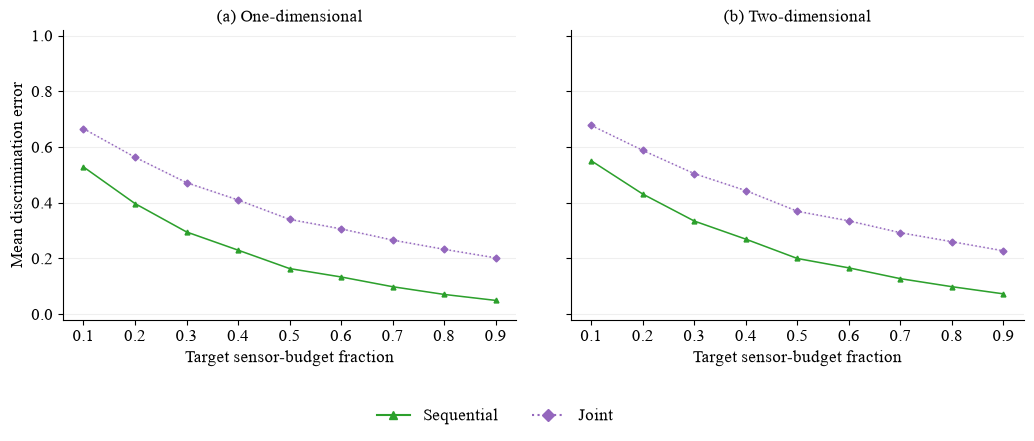

**Table 1 — Field-Family Comparison**

| Dimension | Field Family | Sequential Mean Error | Joint Mean Error |
|---|---|---:|---:|
| 1D | Gaussian | 0.213830 | 0.379557 |
| 1D | Sinusoidal | 0.208325 | 0.345788 |
| 1D | Quadratic | 0.202658 | 0.390485 |
| 2D | Gaussian | 0.253115 | 0.405842 |
| 2D | Sinusoidal | 0.252594 | 0.381478 |
| 2D | Quadratic | 0.207412 | 0.401453 |

In [6]:
import importlib
import comparison.reporting as _reporting
_reporting = importlib.reload(_reporting)
figure, table_markdown = _reporting.make_report(ROWS, OUTPUT, CONFIG)
display(Markdown('**Figure 1 — Sequential vs. Joint Error**'))
display(figure)
plt.close(figure)
display(Markdown('**Table 1 — Field-Family Comparison**'))
display(Markdown(table_markdown))


In [7]:
# Compare each unique instance/budget once; lower error wins.
import math

TIE_TOLERANCE = 1e-9
matched = {}
for row in ROWS:
    key = (row['dimension'], row['instance_id'], row['N'])
    if key in matched:
        raise ValueError(f'Duplicate instance/budget: {key}')
    difference = row['sequential_error'] - row['joint_error']
    if not math.isfinite(difference):
        raise ValueError(f'Nonfinite error difference: {key}')
    matched[key] = difference

lines = ['| Dimension | Comparisons | Sequential better | Joint better | Ties |',
         '|---|---:|---:|---:|---:|']
for label, dimension in [('Overall', None), ('1D', 1), ('2D', 2)]:
    differences = [difference for key, difference in matched.items()
                   if dimension is None or key[0] == dimension]
    count = len(differences)
    sequential_wins = sum(d < -TIE_TOLERANCE for d in differences)
    joint_wins = sum(d > TIE_TOLERANCE for d in differences)
    ties = count - sequential_wins - joint_wins
    percentages = [f'{100 * n / count:.2f}%' if count else '—'
                   for n in (sequential_wins, joint_wins, ties)]
    lines.append(f'| {label} | {count:,} | ' + ' | '.join(percentages) + ' |')

display(Markdown('**Sequential vs. Joint: percentage of comparisons won**'))
display(Markdown('\n'.join(lines)))
display(Markdown('Each matched instance and unique sensor count has equal weight. '
                 f'Absolute error differences of at most {TIE_TOLERANCE:g} count as ties.'))


**Sequential vs. Joint: percentage of comparisons won**

| Dimension | Comparisons | Sequential better | Joint better | Ties |
|---|---:|---:|---:|---:|
| Overall | 55,249 | 98.56% | 0.12% | 1.32% |
| 1D | 28,069 | 98.64% | 0.09% | 1.28% |
| 2D | 27,180 | 98.48% | 0.16% | 1.36% |

Each matched instance and unique sensor count has equal weight. Absolute error differences of at most 1e-09 count as ties.